# Лабораторная работа №3. Manifold learning

**Цель работы:** изучить методы нелинейного снижения размерности и сравнить MDS, Isomap, LLE и PCA на искусственных многообразиях и наборе рукописных цифр.

## 1. Визуализация связей


In [1]:
#@title Pairwise distances
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np

def make_hello(N=1000, rseed=42):
  # Make a plot with "HELLO" text; save as PNG
  fig, ax = plt.subplots(figsize=(4, 1))
  fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
  ax.axis('off')
  ax.text(0.5, 0.4, 'HELLO', va='center', ha='center', weight='bold', size=85)
  fig.savefig('hello.png')
  plt.close(fig)
  # Open this PNG and draw random points from it
  from matplotlib.image import imread
  data = imread('hello.png')[::-1, :, 0].T
  rng = np.random.RandomState(rseed)
  X = rng.rand(4 * N, 2)
  i, j = (X * data.shape).astype(int).T
  mask = (data[i, j] < 1)
  X = X[mask]
  X[:, 0] *= (data.shape[0] / data.shape[1])
  X = X[:N]
  return X[np.argsort(X[:, 0])]

X = make_hello(1000)
colorize = dict(c=X[:, 0], cmap=plt.get_cmap('rainbow', 5))

import numpy as np

# arrange "hello" in non-linear, S-shaped way
def make_hello_s_curve(X):
  t = (X[:, 0] - 2) * 0.75 * np.pi
  x = np.sin(t)
  y = X[:, 1]
  z = np.sign(t) * (np.cos(t) - 1)
  return np.vstack((x, y, z)).T
XS = make_hello_s_curve(X)

from plotly.subplots import make_subplots
import plotly.graph_objects as go
colors = ['rgb(' + np.array2string(c[:-1], formatter={'float_kind':lambda x:  "%.0f" % (x * 255)}, separator=',')[1:-1] + ')' for c in colorize['cmap'](0.255*colorize['c'])]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]])

fig.add_trace(go.Scatter3d(x=XS[:, 0], y=XS[:, 1], z=XS[:, 2],
                           mode='markers', name='datapoints (LEFT)',
                           marker=dict(
                              size=5,
                              opacity=0.8,
                              color=colors
                            )
                           ), row=1, col=1)
fig.add_trace(go.Scatter3d(x=XS[:, 0], y=XS[:, 1], z=XS[:, 2],
                           mode='markers', name='datapoints (RIGHT)',
                           marker=dict(
                              size=5,
                              opacity=0.8,
                              color=colors
                            )
                           ), row=1, col=2)

# construct lines for LLE
from sklearn.neighbors import NearestNeighbors

N_neighbours = 100

rng = np.random.RandomState(42)
ind = rng.permutation(len(X))
nbrs = NearestNeighbors(n_neighbors=N_neighbours, radius=100.0).fit(XS).kneighbors(XS[ind[:100]])[1]
lines_LLE = []
for i in range(100):
  for j in nbrs[i]:
    lines_LLE = lines_LLE + [XS[ind[i]], XS[j], np.array([None, None, None])]
lines_LLE = np.array(lines_LLE)

fig.add_trace(go.Scatter3d(
    x=lines_LLE[:, 0],
    y=lines_LLE[:, 1],
    z=lines_LLE[:, 2],
    mode='lines', opacity=0.2,
    line={'color': 'rgb(0,0,0)', 'width': 1},
    name='LLE connections'
), row=1, col=1)

# construct lines for MDS
lines_MDS = []
for i in ind[:100]:
  for j in ind[100:200]:
    lines_MDS = lines_MDS + [XS[i], XS[j], np.array([None, None, None])]
lines_MDS = np.array(lines_MDS)

fig.add_trace(go.Scatter3d(
    x=lines_MDS[:, 0],
    y=lines_MDS[:, 1],
    z=lines_MDS[:, 2],
    mode='lines', opacity=0.1,
    line={'color': 'rgb(0,0,0)', 'width': 1},
    name='MDS connections'
), row=1, col=2)

fig.show()


#Sklearn manifold learning methods

Используйте следующий пример, чтобы получить представление о том, как работает многообразное обучение. 
* Попробуйте разные параметры для MDS и Isomap. Обратите внимание, что `n_neighbours` **значительно** меняет результат. Попробуйте разные значения, чтобы увидеть эффект 
* Реализуйте свою собственную поверхность, изменив функцию custom(X)`. В качестве примера приведена рулетка.

In [2]:
from sklearn.manifold import LocallyLinearEmbedding, MDS, Isomap

def linear_embedding(datapoints, n_neighbors=12):
    model = LocallyLinearEmbedding(
        n_neighbors=n_neighbors,
        n_components=2,
        method='modified',
        eigen_solver='auto'
    )
    return model.fit_transform(datapoints)

def multidim_scaling(datapoints):
    # MDS сам вычисляет евклидовы расстояния по переданным точкам.
    model = MDS(
        n_components=2,
        random_state=42,
        n_init=1,
        max_iter=100,
        normalized_stress='auto'
    )
    return model.fit_transform(datapoints)

def isomap(datapoints, n_neighbors=12):
    model = Isomap(n_components=2, n_neighbors=n_neighbors)
    return model.fit_transform(datapoints)

def custom(X):
    """Моя поверхность: волнистая лента, заданная двумя параметрами."""
    x_min, x_max = X[:, 0].min(), X[:, 0].max()
    y_min, y_max = X[:, 1].min(), X[:, 1].max()
    u = 2 * np.pi * (X[:, 0] - x_min) / (x_max - x_min)
    v = 2 * (X[:, 1] - y_min) / (y_max - y_min) - 1
    x = u
    y = v
    z = 0.7 * np.sin(2 * u) + 0.25 * np.cos(np.pi * v)
    return np.column_stack((x, y, z))


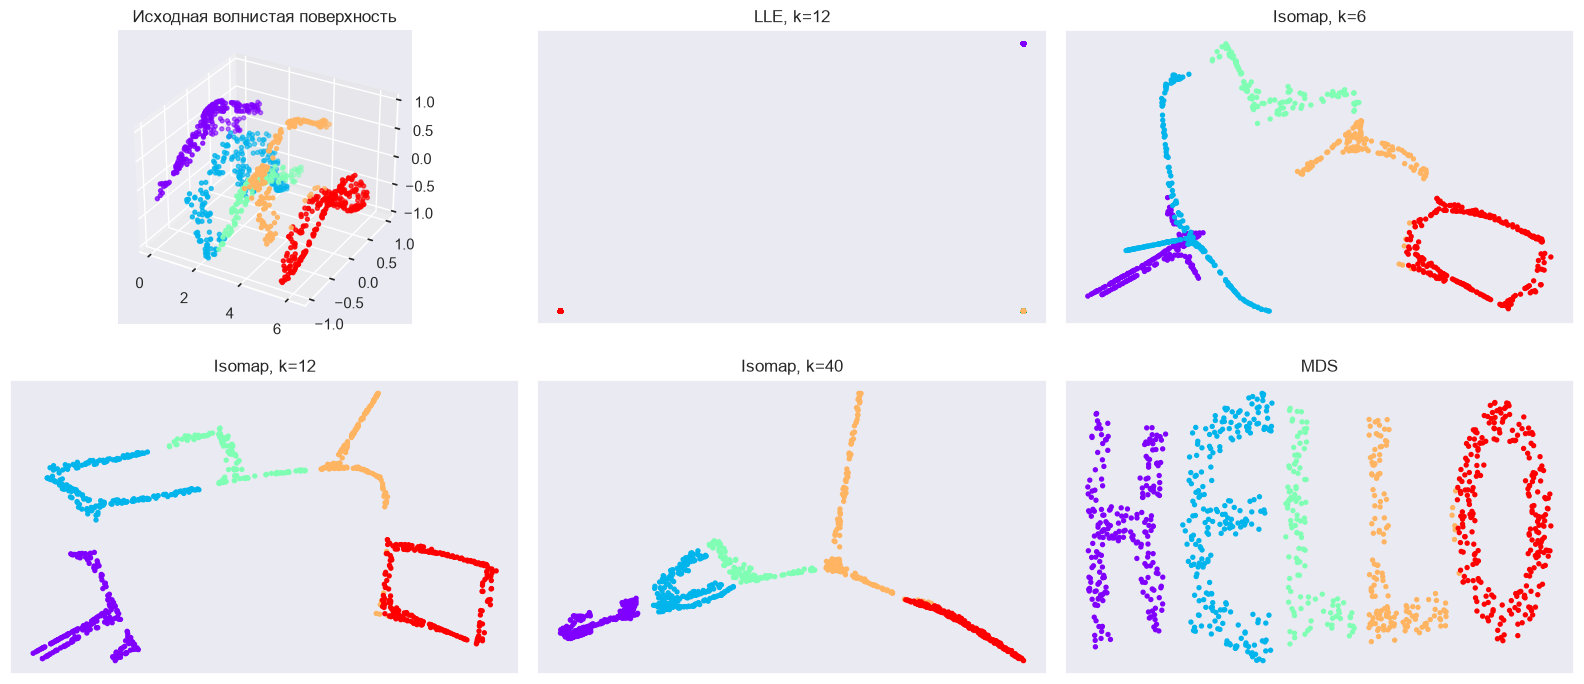

In [3]:
# Сравнение методов и влияния числа соседей на моей волнистой поверхности
from sklearn.manifold import LocallyLinearEmbedding, MDS, Isomap
from scipy.sparse import SparseEfficiencyWarning
import warnings

# Раздельные буквы HELLO образуют несвязные компоненты; это ожидаемая
# особенность демонстрационного набора, а не ошибка вычислений.
warnings.filterwarnings('ignore', message='The number of connected components')
warnings.filterwarnings('ignore', category=SparseEfficiencyWarning)

surface = custom(X)
experiments = [
    ('LLE, k=12', LocallyLinearEmbedding(n_neighbors=12, n_components=2,
                                         method='modified', eigen_solver='auto')),
    ('Isomap, k=6', Isomap(n_neighbors=6, n_components=2)),
    ('Isomap, k=12', Isomap(n_neighbors=12, n_components=2)),
    ('Isomap, k=40', Isomap(n_neighbors=40, n_components=2)),
    ('MDS', MDS(n_components=2, random_state=42, n_init=1, max_iter=100,
                normalized_stress='auto', init='classical_mds')),
]

fig = plt.figure(figsize=(16, 7))
ax = fig.add_subplot(2, 3, 1, projection='3d')
ax.scatter(surface[:, 0], surface[:, 1], surface[:, 2], **colorize, s=8)
ax.set_title('Исходная волнистая поверхность')

embeddings = {}
for plot_index, (name, model) in enumerate(experiments, start=2):
    embedding = model.fit_transform(surface)
    embeddings[name] = embedding
    ax = fig.add_subplot(2, 3, plot_index)
    ax.scatter(embedding[:, 0], embedding[:, 1], **colorize, s=8)
    ax.set_title(name)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()


### Наблюдение

Я использовал собственную нелинейную поверхность — волнистую ленту. При малом `n_neighbors` Isomap лучше следует локальной структуре, но граф может получиться недостаточно связным. При слишком большом числе соседей возникают связи через изгибы, и развёртка становится ближе к глобальной евклидовой проекции. MDS учитывает все попарные евклидовы расстояния и поэтому не знает, что расстояние нужно измерять вдоль поверхности. LLE сохраняет локальные линейные отношения и также зависит от размера окрестности.

## 2. Снижение размерности набора digits до трёх компонент


## Набор данных digits


* Запустите следующий код, чтобы загрузить набор данных MNIST и добавить шум 

In [4]:
from sklearn.datasets import load_digits
import numpy as np

digits = load_digits()
clean_data, target = digits.data, digits.target

# Добавляю воспроизводимый гауссов шум со стандартным отклонением 5.
rng = np.random.default_rng(42)
data = rng.normal(loc=clean_data, scale=5.0)

print('Размер данных:', data.shape)
print('Число классов:', np.unique(target).size)


Размер данных: (1797, 64)
Число классов: 10


* Выполните следующие функции, чтобы уменьшить размеры `данных` до 3. Ожидается, что результат будет иметь вид `(1797, 3)`.

In [5]:
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')

from functools import lru_cache
import warnings

warnings.filterwarnings('ignore', message='Could not find the number of physical cores')
from sklearn.manifold import Isomap, MDS
from sklearn.decomposition import PCA

@lru_cache(maxsize=None)
def projected_mds():
    model = MDS(
        n_components=3,
        random_state=42,
        n_init=1,
        max_iter=60,
        eps=1e-3,
        normalized_stress='auto',
        init='classical_mds',
        n_jobs=1
    )
    return model.fit_transform(data)

@lru_cache(maxsize=None)
def projected_isomap():
    model = Isomap(n_components=3, n_neighbors=12, n_jobs=1)
    return model.fit_transform(data)

@lru_cache(maxsize=None)
def projected_PCA():
    model = PCA(n_components=3, random_state=42)
    return model.fit_transform(data)

for name, projection in {
    'MDS': projected_mds(),
    'Isomap': projected_isomap(),
    'PCA': projected_PCA(),
}.items():
    print(f'{name}: {projection.shape}')


MDS: (1797, 3)
Isomap: (1797, 3)
PCA: (1797, 3)


* Запустите код визуализации, чтобы увидеть результат.

In [6]:
#@title Visualization
import numpy as np
from plotly.subplots import make_subplots
import plotly.graph_objects as go

cmap = {0: 'rgba(0,0,255,255)', 1: 'rgba(0,255,0,255)', 2: 'rgba(255,0,0,255)',
        3: 'rgba(0,0,128,255)', 4: 'rgba(0,128,0,255)', 5: 'rgba(128,0,255)',
        6: 'rgba(0,0,64,255)', 7: 'rgba(0,64,0,255)', 8: 'rgba(64,0,0,255)',
        9: 'rgba(0,0,0,255)'}
colors = [cmap[int(d)] for d in digits.target]

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]])

iso_proj = projected_isomap()
fig.add_trace(go.Scatter3d(x=iso_proj[:, 0], y=iso_proj[:, 1], z=iso_proj[:, 2],
                           mode='markers',
                           marker=dict(size=4, color=colors)),
              row=1, col=1)

pca_proj = projected_PCA()
fig.add_trace(go.Scatter3d(x=pca_proj[:, 0], y=pca_proj[:, 1], z=pca_proj[:, 2],
                           mode='markers',
                           marker=dict(size=4, color=colors)),
              row=1, col=2)

fig.update_layout(width=1200, height=600, autosize=False,
                  title_text="3-component Isomap (left) and PCA (right) for digits",
                  scene={"xaxis": {"title": "component 1"},
                         "yaxis": {"title": "component 2"},
                         "zaxis": {"title": "component 3"}},
                  showlegend=False)

fig.show()

### Интерпретация проекций

Каждая функция вернула массив формы `(1797, 3)`. Цвет соответствует истинному классу цифры. Полного разделения классов в трёх измерениях ожидать не следует: шум велик, а разные цифры могут иметь похожее написание. PCA показывает линейную структуру дисперсии; Isomap пытается сохранить расстояния вдоль графа соседей; MDS оптимизирует глобальное соответствие расстояний.

## 3. Классификация до и после снижения размерности

Для всех вариантов я использую один классификатор SVM с RBF-ядром и одинаковое разбиение данных. Это позволяет сравнивать именно представления. Важное ограничение: `sklearn.manifold.MDS` не имеет метода `transform` для новых объектов. Поэтому MDS-, Isomap- и PCA-проекции ниже заранее построены без учёта меток, после чего одни и те же индексы разделены на train/test. Для MDS это **трансдуктивная** оценка: геометрия тестовых объектов участвовала в построении проекции, хотя их метки не использовались.


* разделить набор данных на поезд и тест 
* Создайте модели: 
   - любой классификатор (простой) 
   - PCA + любой классификатор
   - MDP + любой классификатор  
   - Изомап + любой классификатор 
* Обучите модели 
* Попробуйте сдеать классификацию

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

indices = np.arange(len(data))
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.3,
    random_state=42,
    stratify=target
)
y_train, y_test = target[train_idx], target[test_idx]

def classify(features):
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel='rbf', C=5, gamma='scale')
    )
    model.fit(features[train_idx], y_train)
    return model.predict(features[test_idx])

l_simple = classify(data)
l_mds = classify(projected_mds())
l_isomap = classify(projected_isomap())
l_pca = classify(projected_PCA())

def get_results():
    names = ['Исходные 64 признака', 'MDS (3 компоненты)',
             'Isomap (3 компоненты)', 'PCA (3 компоненты)']
    labels = [l_simple, l_mds, l_isomap, l_pca]
    return y_test, names, labels

for name, labels in zip(get_results()[1], get_results()[2]):
    print(f'{name}: accuracy = {accuracy_score(y_test, labels):.4f}')


Исходные 64 признака: accuracy = 0.8833
MDS (3 компоненты): accuracy = 0.6056
Isomap (3 компоненты): accuracy = 0.6981
PCA (3 компоненты): accuracy = 0.6278


* Запустите код визуализации, чтобы увидеть матрицы путаницы.

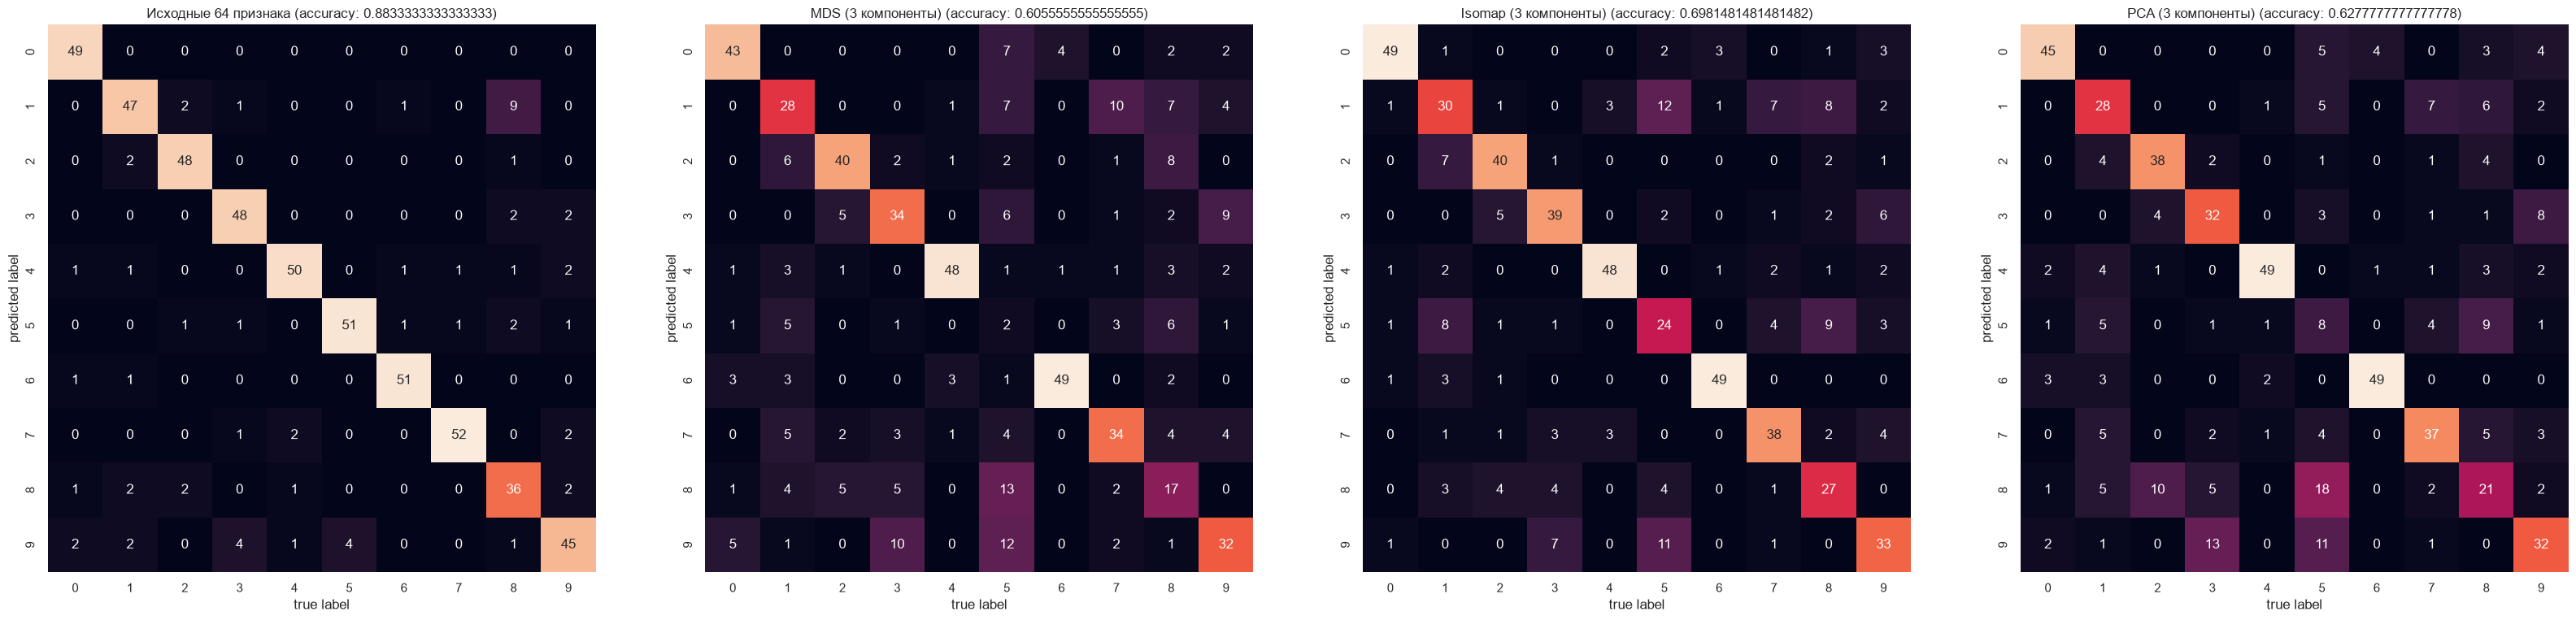

In [8]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

trg, names, labels = get_results()
num_plots = len(names)
fig = plt.figure(figsize=(10 * num_plots, 10))

for idx in range(num_plots):
  plt.subplot(1, num_plots, 1 + idx)
  mat = confusion_matrix(trg, labels[idx])
  sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=[i for i in range(10)],
            yticklabels=[i for i in range(10)])
  plt.ylim(10.0, 0.0)
  plt.xlabel('true label')
  plt.ylabel('predicted label')

  plt.title(names[idx] + " (accuracy: " + str(accuracy_score(trg, labels[idx])) + ")")

## Вывод

В ходе работы я изучил методы MDS, LLE и Isomap и сравнил их с PCA. Эксперимент с волнистой поверхностью показал, что методы manifold learning действительно могут восстанавливать двумерную структуру нелинейно вложенной поверхности, но результат Isomap и LLE сильно зависит от числа соседей. MDS ориентируется на глобальные евклидовы расстояния и поэтому хуже учитывает изгибы многообразия.

На зашумлённом наборе digits классификатор на исходных 64 признаках дал accuracy `0.8833`. После снижения до трёх компонент получены результаты: Isomap — `0.6981`, PCA — `0.6278`, MDS — `0.6056`. Следовательно, сильное сжатие приводит к заметной потере информации. Среди проекций результаты зависят от структуры данных и параметров. PCA является быстрым и устойчивым базовым методом, а Isomap полезен, когда данные действительно лежат на связном нелинейном многообразии. Для практической оценки на новых данных необходимо учитывать наличие метода `transform`: он есть у PCA и Isomap, но отсутствует у стандартного MDS из `scikit-learn`.
